# CAMS auxiliary data

GRS takes the state of the atmosphere at the time of the image from the
[CAMS global atmospheric composition forecasts](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts)
of the Copernicus Atmosphere Monitoring Service, distributed by the Atmosphere Data Store (ADS):

| CAMS variables | use in GRS |
|---|---|
| surface pressure `sp`, mean sea level pressure `msl` | Rayleigh scattering (pressure at the surface, or at the DEM altitude) |
| total columns of O$_3$ `gtco3`, NO$_2$ `tcno2`, CO `tcco`, CH$_4$ `tc_ch4`, water vapour `tcwv` | gaseous transmittance |
| aerosol optical depth at 469, 550, 670, 865 and 1240 nm `aod<wl>` | choice of the aerosol model, first guess of the AOT |
| AOD at 550 nm of each aerosol species (`duaod550`, `ssaod550`...) | information |
| 10 m wind `u10`, `v10` | sea surface roughness (sunglint) |

This notebook shows how to download these data and what GRS reads from them, on the Sentinel-2 image
processed in the {doc}`processing tutorial <../processing>`.

## 1. Access to the Atmosphere Data Store

1. Create an account on the [ADS](https://ads.atmosphere.copernicus.eu) and accept the licence of the
   dataset (*Download* tab of the dataset page).
2. Copy your API key from your ADS profile into `~/.cdsapirc`:

   ```
   url: https://ads.atmosphere.copernicus.eu/api
   key: <your-personal-access-token>
   ```
3. Install the client: `pip install "cdsapi>=0.7"` (installed with GRS).

The download cells below are not run in this documentation (`DOWNLOAD = False`): set `DOWNLOAD = True`
to run them.

In [1]:
import os
import calendar

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import cdsapi
from osgeo import gdal
import GRSdriver
import grs

gdal.UseExceptions()

opj = os.path.join
print(f'grs:       {grs.__version__}')
print(f'GRSdriver: {GRSdriver.__version__}')

grs:       3.1.0
GRSdriver: 1.0.10


In [2]:
# settings: edit the paths to run the notebook on your own data
DOWNLOAD = False   # True to send the requests to the ADS

l1c_file = ('/data/satellite/Sentinel-2/L1C/30TWT/2020/04/11/'
            'S2B_MSIL1C_20200411T110619_N0500_R137_T30TWT_20230509T002033.SAFE')
cams_dir = '/data/cams/world'                              # monthly files cams_forecast_<yyyy>-<mm>.nc
cams_file = opj(cams_dir, 'cams_forecast_2020-04.nc')     # file of the month of the image

## 2. Download the data of one image

{class}`~grs.cams.CamsProduct` knows the date and the footprint of an image: its method
{meth}`~grs.cams.CamsProduct.cams_download` requests the forecasts of the day (runs of 00:00 and
12:00 UTC, lead times 0 to 9 h) over the footprint enlarged by 1°, and writes them into
`<dir>/<date>-forecast<suffix>.nc`. The image is opened at 60 m with GRSdriver, which is enough
to get its date and footprint.

In [3]:
l1c = GRSdriver.Sentinel2Driver(l1c_file, resolution=60)
l1c.load_product()
prod = grs.Product(l1c.prod)

cams_image = grs.CamsProduct(prod.raster, dir=cams_dir, suffix='_30TWT')
print('date:', cams_image.date_str)
print('area [N, W, S, E]:', np.round(cams_image.area, 2))
print('output file:', cams_image.filepath)
if DOWNLOAD:
    cams_image.cams_download()

date: 2020-04-11
area [N, W, S, E]: [48.85 -4.   45.86 -0.53]
output file: /data/cams/world/2020-04-11-forecast_30TWT.nc


## 3. Download monthly files

To process many images, it is simpler to download one file per month over a large area (here the
whole globe, as used for the CAMS files of this documentation) and to give the file of the month to
GRS. The variables are those of {class}`~grs.cams.CamsProduct`. The scripts of the
[`ecmwf/`](https://github.com/CNES/GRSprocessor/tree/main/ecmwf) folder of the repository do the same
for long periods, on a computing cluster.

In [4]:
def download_month(year, month, odir, area=(90, -180, -90, 180)):
    """Download the CAMS forecasts of one month into <odir>/cams_forecast_<yyyy>-<mm>.nc."""
    ndays = calendar.monthrange(year, month)[1]
    filepath = opj(odir, f'cams_forecast_{year:04d}-{month:02d}.nc')
    if os.path.exists(filepath):
        return filepath
    os.makedirs(odir, exist_ok=True)
    cdsapi.Client().retrieve(
        'cams-global-atmospheric-composition-forecasts',
        {'date': f'{year:04d}-{month:02d}-01/{year:04d}-{month:02d}-{ndays:02d}',
         'type': 'forecast',
         'format': 'netcdf',
         'variable': cams_image.variable,     # variables used by GRS
         'time': ['00:00', '12:00'],
         'leadtime_hour': ['0', '3', '6', '9'],
         'area': list(area)},
        filepath)
    return filepath


if DOWNLOAD:
    for month in (4, 5, 6):
        print(download_month(2020, month, cams_dir))

## 4. What GRS reads from a CAMS file

{meth}`~grs.cams.CamsProduct.load` selects the forecasts of the day of the image, interpolates them
to the time of the acquisition and crops them to the footprint (about 0.4° resolution, i.e. a few
CAMS cells over a Sentinel-2 tile). The wind module `wind` is computed from `u10` and `v10`.

In [5]:
cams = grs.CamsProduct(prod.raster, cams_file=cams_file)
cams.load()
cams.raster

<xarray.Dataset> Size: 27kB
Dimensions:      (y: 12, x: 12)
Coordinates:
  * y            (y) float64 96B 5.3e+06 5.29e+06 5.28e+06 ... 5.2e+06 5.19e+06
  * x            (x) float64 96B 5e+05 5.1e+05 5.199e+05 ... 5.998e+05 6.098e+05
    time         datetime64[ns] 8B 2020-04-11T11:06:19
    spatial_ref  int64 8B 0
Data variables: (12/23)
    v10          (y, x) float64 1kB 1.05 0.9962 0.928 ... 0.7853 0.7242 0.6963
    t2m          (y, x) float64 1kB 292.0 292.2 292.5 ... 291.6 292.3 292.7
    msl          (y, x) float64 1kB 1.021e+05 1.021e+05 ... 1.021e+05 1.021e+05
    sp           (y, x) float64 1kB 1.012e+05 1.012e+05 ... 1.017e+05 1.016e+05
    amaod550     (y, x) float64 1kB 0.006055 0.006171 ... 0.01182 0.01241
    bcaod550     (y, x) float64 1kB 0.008366 0.008281 ... 0.009053 0.008662
    ...           ...
    tc_ch4       (y, x) float64 1kB 0.01021 0.01022 0.01022 ... 0.01034 0.01033
    tcno2        (y, x) float64 1kB 2.046e-06 2.074e-06 ... 1.961e-06 1.945e-06
    gtco3        (y, x) float64 1kB 0.007084 0.00705 ... 0.006584 0.006572
    tcwv         (y, x) float64 1kB 14.69 14.62 14.57 ... 13.58 13.47 13.36
    u10          (y, x) float64 1kB -1.032 -1.041 -1.033 ... -0.3523 -0.4041
    wind         (y, x) float64 1kB 1.472 1.441 1.389 ... 0.8389 0.8053 0.8051
Attributes:
    Conventions:  CF-1.6
    history:      2024-02-20 13:17:13 GMT by grib_to_netcdf-2.25.1: /opt/ecmw...

Maps of the CAMS variables over the tile (aerosol optical depth by species and in total,
meteorology, gas columns, wind components):

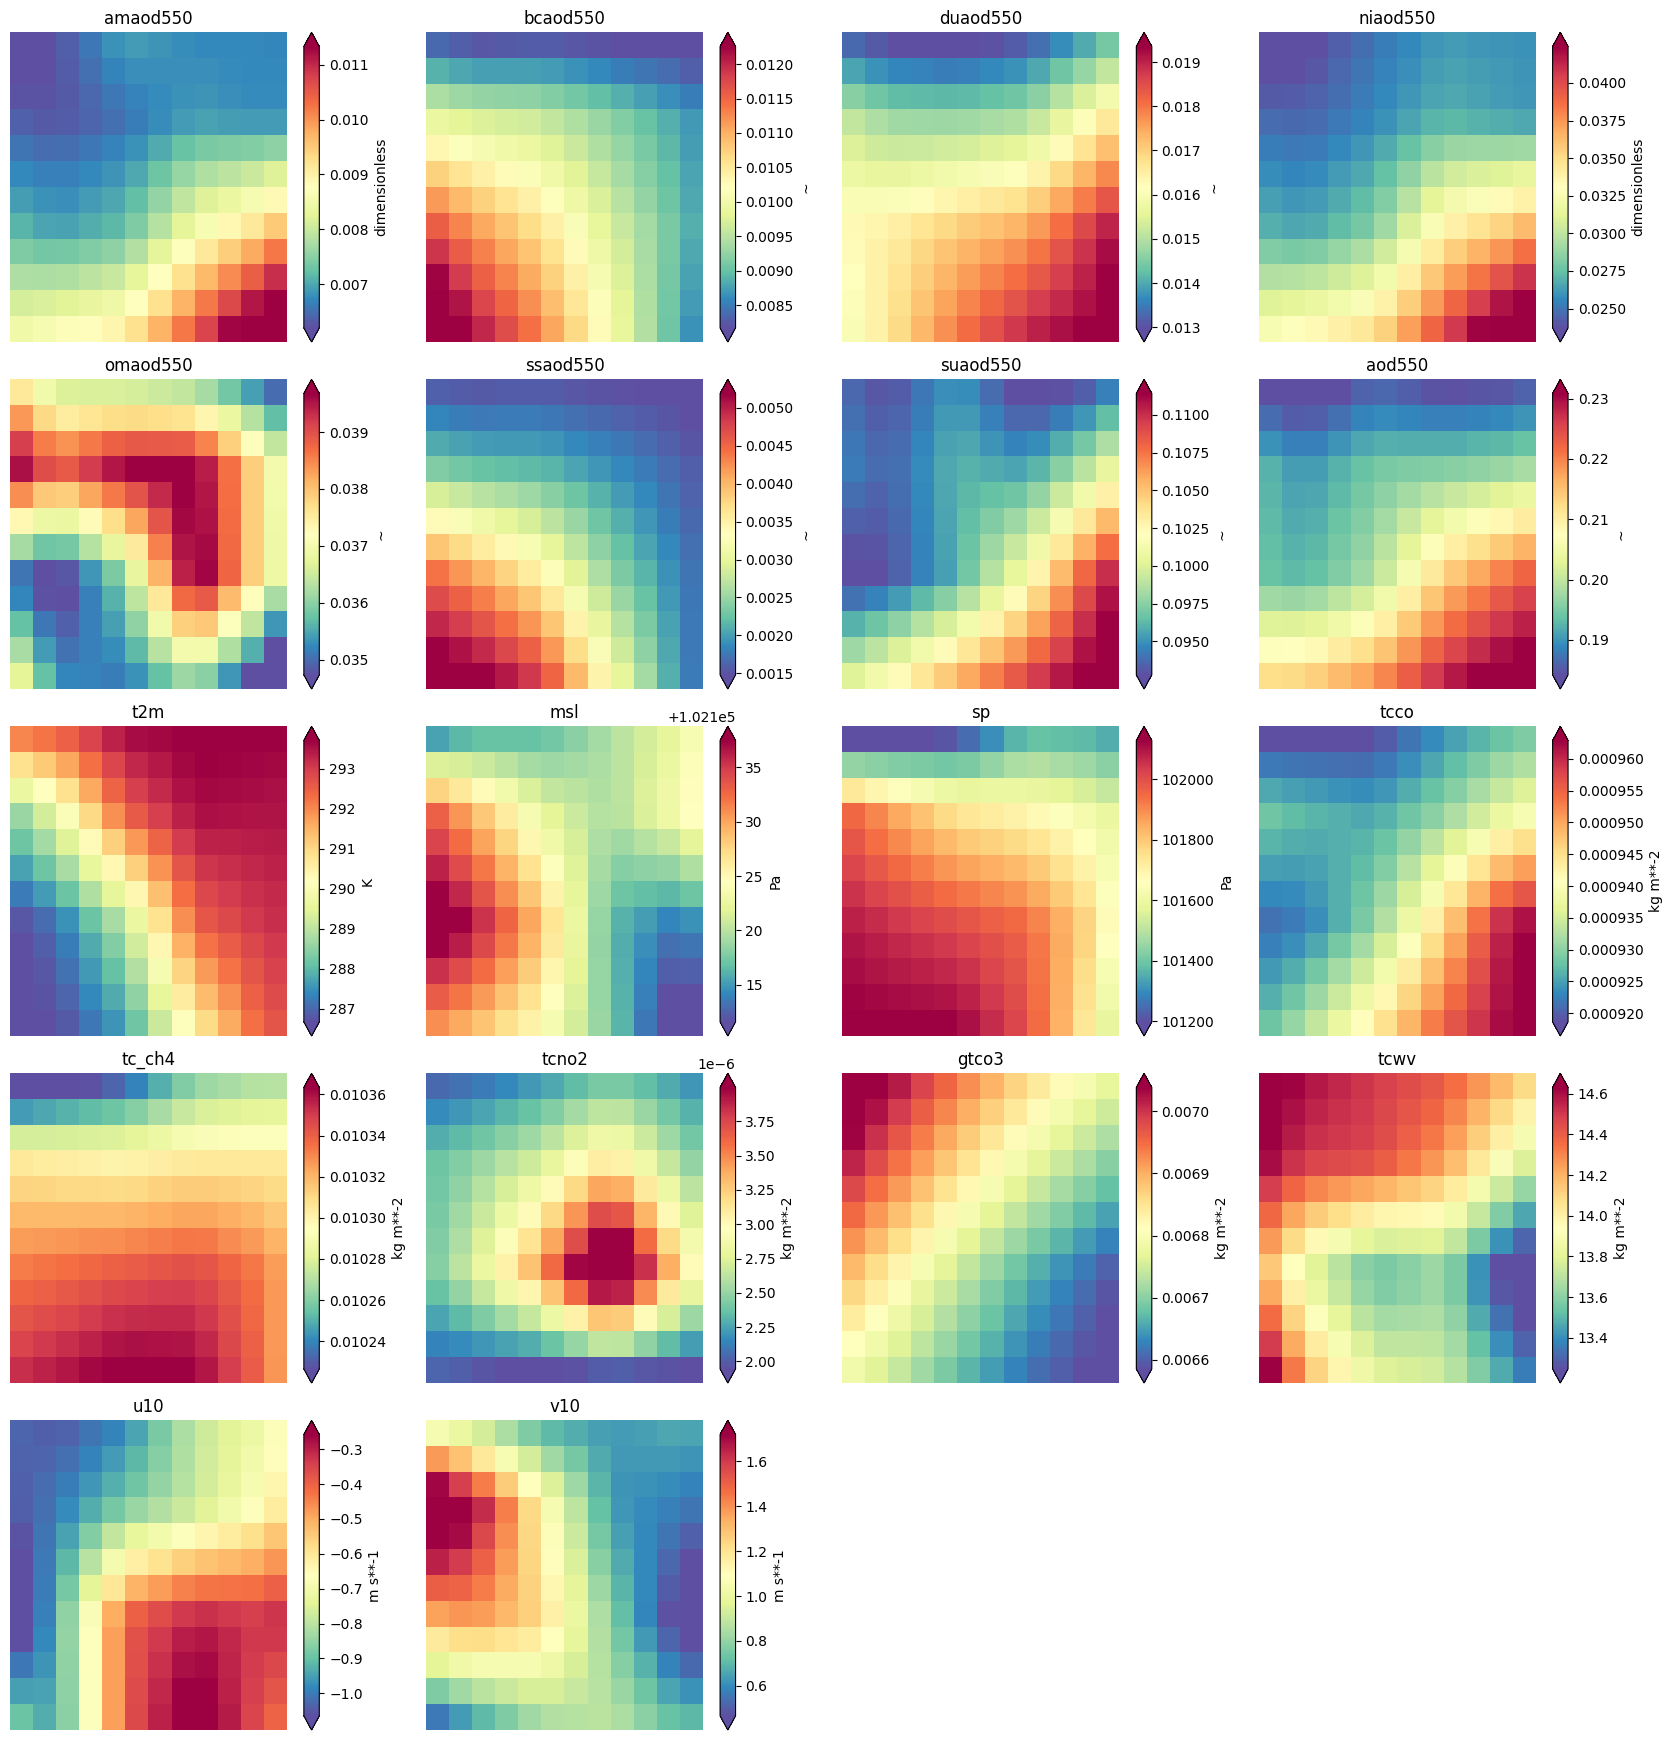

In [6]:
fig, axs = cams.plot_params(cmap='Spectral_r')

### Spectral aerosol optical depth

GRS compares the spectral shape of the CAMS AOD, normalized at 550 nm, with those of the OPAC aerosol
models of its look-up tables to choose the aerosol model (see {doc}`../../methods`). The Ångström
exponent $\alpha$ of the CAMS spectrum, between 469 and 865 nm, indicates the size of the particles
(small $\alpha$: coarse particles such as dust or sea salt).

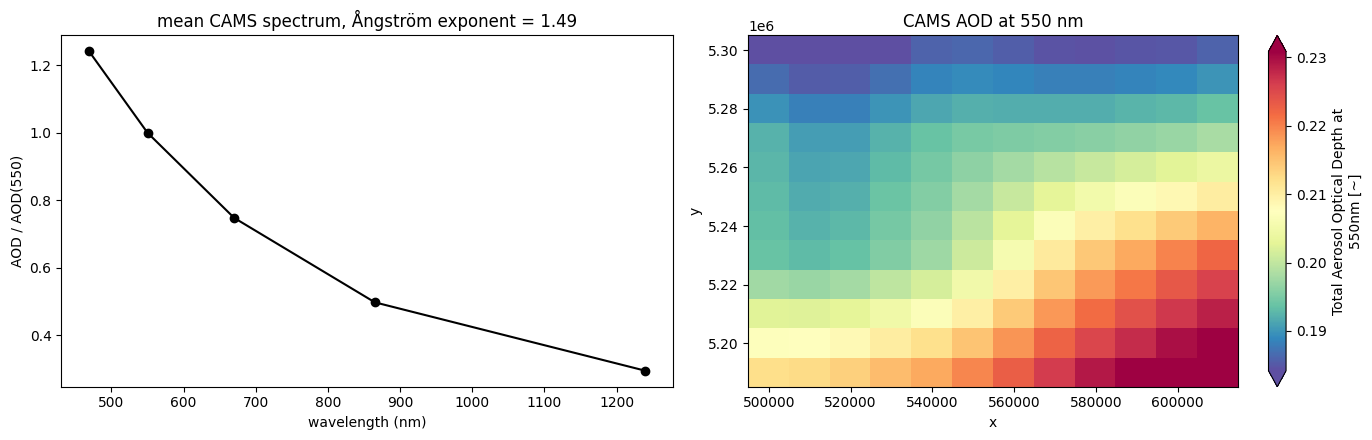

In [7]:
aod = cams.cams_aod.mean(['x', 'y'])
alpha = -np.log(aod.sel(wl=865) / aod.sel(wl=469)) / np.log(865 / 469)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
(aod / aod.sel(wl=550)).plot(ax=axs[0], marker='o', color='black')
axs[0].set(ylabel='AOD / AOD(550)', xlabel='wavelength (nm)',
           title=f'mean CAMS spectrum, Ångström exponent = {float(alpha):.2f}')
cams.raster.aod550.plot.imshow(ax=axs[1], cmap='Spectral_r', robust=True)
axs[1].set_title('CAMS AOD at 550 nm')
plt.tight_layout()

### Wind over the image

The CAMS wind sets the roughness of the sea surface, i.e. the width of the sunglint pattern
(Cox and Munk slope distribution). Overlay on the true-colour image (top-of-atmosphere reflectance):

Text(0.5, 1.0, 'CAMS 10 m wind, 2020-04-11')

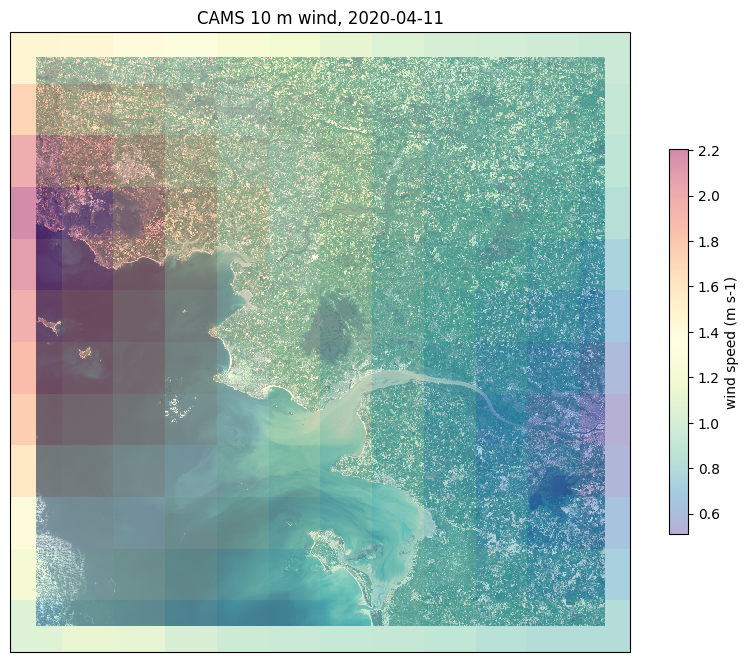

In [8]:
epsg = prod.raster.rio.crs.to_epsg()   # UTM zone of the tile, e.g. 32630
proj = ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': proj})
prod.raster.bands.sel(wl=[665, 560, 490], method='nearest').plot.imshow(
    rgb='wl', robust=True, ax=ax, transform=proj)
cams.raster.wind.plot.imshow(ax=ax, transform=proj, alpha=0.45, cmap='Spectral_r',
                             cbar_kwargs={'shrink': 0.5, 'label': 'wind speed (m s-1)'})
ax.set_title(f'CAMS 10 m wind, {cams.date_str}')

## 5. Use in GRS

Give the CAMS file to the processing, from the command line or from Python:

```bash
grs S2B_MSIL1C_20200411T110619_N0500_R137_T30TWT_20230509T002033.SAFE --cams_file cams_forecast_2020-04.nc
```

```python
process = grs.Process()
process.execute(l1c_file, cams_file=cams_file, resolution=20)
```

The CAMS data used are exported in the `ancillary` group of the output product (see {doc}`../../usage`).